<a href="https://colab.research.google.com/github/RyuuBatataa/Estrutura_de_Dados_II/blob/main/Atividade_Grafos_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prática de Grafos - Unidade III
**Disciplina:** Estrutura de Dados II | **Professora:** Kadidja Valéria  
**Estudante:** Liz Cristina Ferreira  
**Plataforma utilizada:** Google Colab (Python + bibliotecas NetworkX e Matplotlib)

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

### Atividade 1 - Desenhando um grafo

--- Dados do Grafo (Atividade 1) ---
Vértices (V): [1, 2, 3, 4, 5]
Arestas (E): [(1, 2), (1, 4), (1, 5), (2, 3), (3, 4), (4, 4)]
Ordem (total de vértices): 5
Tamanho (total de arestas): 6
Laço encontrado: [(4, 4)]

Grau de cada vértice:
  Vértice 1: grau 3
  Vértice 2: grau 2
  Vértice 3: grau 2
  Vértice 4: grau 4
  Vértice 5: grau 1


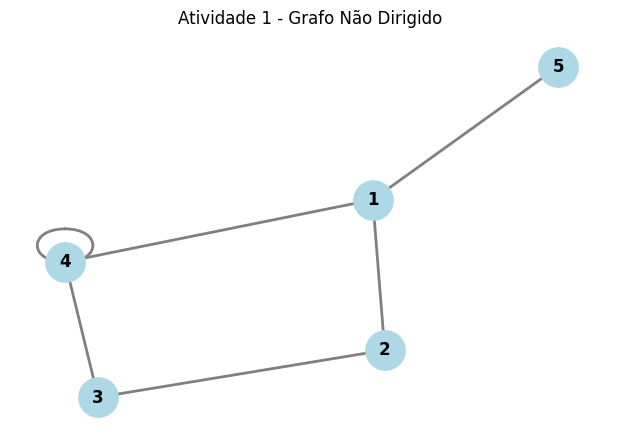

In [10]:
# Instanciando um grafo não dirigido
G1 = nx.Graph()

# Definindo as listas de vértices (V) e arestas (E) passadas no roteiro
V1 = [1, 2, 3, 4, 5]
E1 = [(1, 2), (1, 4), (1, 5), (2, 3), (3, 4), (4, 4)]

# Inserindo os vértices e as conexões na estrutura do grafo
G1.add_nodes_from(V1)
G1.add_edges_from(E1)

# Exibindo os dados solicitados usando as funções nativas do NetworkX
print("--- Dados do Grafo (Atividade 1) ---")
print(f"Vértices (V): {list(G1.nodes())}")
print(f"Arestas (E): {list(G1.edges())}")
print(f"Ordem (total de vértices): {G1.number_of_nodes()}")
print(f"Tamanho (total de arestas): {G1.number_of_edges()}")

# A função selfloop_edges busca arestas que saem e voltam para o mesmo nó
print(f"Laço encontrado: {list(nx.selfloop_edges(G1))}")

print("\nGrau de cada vértice:")
# O método degree() já contabiliza o laço valendo 2 no cálculo do grau
for vertice, grau in G1.degree():
    print(f"  Vértice {vertice}: grau {grau}")

# Configurações visuais para plotar o grafo
plt.figure(figsize=(6, 4))
pos1 = nx.spring_layout(G1, seed=42) # seed fixa para o desenho não mudar toda vez que rodar
nx.draw(G1, pos1, with_labels=True, node_color='lightblue',
        node_size=800, font_weight='bold', edge_color='gray', width=2)
plt.title("Atividade 1 - Grafo Não Dirigido")
plt.show()

**Respostas e Justificativas - Atividade 1:**

* **Conjuntos:** $V = \{1, 2, 3, 4, 5\}$ e $E = \{(1,2), (1,4), (1,5), (2,3), (3,4), (4,4)\}$.
* **Ordem e Tamanho:** A **ordem é 5** porque o grafo tem 5 vértices no conjunto $V$. O **tamanho é 6** porque existem 6 arestas ligando esses vértices no conjunto $E$.
* **Identificação do laço:** A aresta **$(4,4)$** é um laço, pois ela sai do vértice 4 e se conecta a ele mesmo.
* **Cálculo dos graus:** O grau é a quantidade de arestas que tocam cada vértice, lembrando que o laço conta duas vezes:
  * **Vértice 1:** grau **3** (ligado às arestas $(1,2)$, $(1,4)$ e $(1,5)$).
  * **Vértice 2:** grau **2** (ligado a $(1,2)$ e $(2,3)$).
  * **Vértice 3:** grau **2** (ligado a $(2,3)$ e $(3,4)$).
  * **Vértice 4:** grau **4** (tem 2 arestas normais $(1,4)$ e $(3,4)$, mais o laço $(4,4)$ que soma 2 ao grau, totalizando $1 + 1 + 2 = 4$).
  * **Vértice 5:** grau **1** (ligado apenas à aresta $(1,5)$).

### Atividade 2 - Incidência e adjacência

In [11]:
print("--- Vizinhos (Adjacência) e Arestas Incidentes ---")

# Percorrendo todos os nós do grafo G1 criado na Atividade 1
for v in G1.nodes():
    vizinhos = list(G1.neighbors(v))
    incidentes = list(G1.edges(v))
    print(f"Vértice {v} -> Adjacentes: {vizinhos} | Arestas incidentes: {incidentes}")

# Comprovando os dois exemplos escolhidos na justificativa
print(f"\nExiste aresta direta entre 1 e 2? {G1.has_edge(1, 2)}")
print(f"Existe aresta direta entre 2 e 5? {G1.has_edge(2, 5)}")

--- Vizinhos (Adjacência) e Arestas Incidentes ---
Vértice 1 -> Adjacentes: [2, 4, 5] | Arestas incidentes: [(1, 2), (1, 4), (1, 5)]
Vértice 2 -> Adjacentes: [1, 3] | Arestas incidentes: [(2, 1), (2, 3)]
Vértice 3 -> Adjacentes: [2, 4] | Arestas incidentes: [(3, 2), (3, 4)]
Vértice 4 -> Adjacentes: [1, 3, 4] | Arestas incidentes: [(4, 1), (4, 3), (4, 4)]
Vértice 5 -> Adjacentes: [1] | Arestas incidentes: [(5, 1)]

Existe aresta direta entre 1 e 2? True
Existe aresta direta entre 2 e 5? False


**Respostas e Justificativas - Atividade 2:**

* **Vértices adjacentes e arestas incidentes de cada nó:**
  * **Vértice 1:** Adjacentes: $\{2, 4, 5\}$ | Arestas incidentes: $(1,2), (1,4), (1,5)$.
  * **Vértice 2:** Adjacentes: $\{1, 3\}$ | Arestas incidentes: $(1,2), (2,3)$.
  * **Vértice 3:** Adjacentes: $\{2, 4\}$ | Arestas incidentes: $(2,3), (3,4)$.
  * **Vértice 4:** Adjacentes: $\{1, 3, 4\}$ *(ele é vizinho dele mesmo por causa do laço)* | Arestas incidentes: $(1,4), (3,4), (4,4)$.
  * **Vértice 5:** Adjacentes: $\{1\}$ | Aresta incidente: $(1,5)$.

* **Escolha de dois vértices adjacentes:** **1 e 2**.
  * *Justificativa:* Eles são adjacentes porque existe a aresta $(1,2)$ no conjunto $E$ ligando um ao outro diretamente.
* **Escolha de dois vértices não adjacentes:** **2 e 5**.
  * *Justificativa:* Eles não são adjacentes porque não há nenhuma aresta ligando o 2 direto ao 5 no conjunto $E$. Para sair do 2 e chegar no 5, é preciso passar pelo vértice 1 como intermediário.

### Atividade 3 - Modelagem de uma rede de amizades

--- Graus na Rede de Amizades ---
  João: grau 3 (3 conexões de amizade)
  Carolina: grau 2 (2 conexões de amizade)
  Maria: grau 2 (2 conexões de amizade)
  Marco: grau 1 (1 conexões de amizade)

Pessoa com maior grau: João (grau 3)


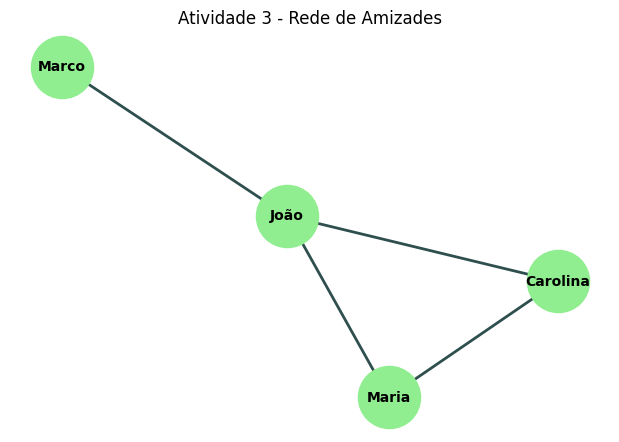

In [12]:
# Usando Graph() (não dirigido) porque amizade vale para os dois lados
G3 = nx.Graph()

# Criando os vértices com os nomes do enunciado e definindo quem é amigo de quem
V3 = ["João", "Carolina", "Maria", "Marco"]
E3 = [("João", "Carolina"), ("João", "Maria"), ("João", "Marco"), ("Carolina", "Maria")]

G3.add_nodes_from(V3)
G3.add_edges_from(E3)

print("--- Graus na Rede de Amizades ---")
# Convertendo os graus para dicionário para facilitar a busca do maior valor
graus_amigos = dict(G3.degree())
for nome, g in graus_amigos.items():
    print(f"  {nome}: grau {g} ({g} conexões de amizade)")

# Pegando a pessoa que tem o maior número de arestas ligadas a ela
mais_conectado = max(graus_amigos, key=graus_amigos.get)
print(f"\nPessoa com maior grau: {mais_conectado} (grau {graus_amigos[mais_conectado]})")

# Desenhando o grafo da rede
plt.figure(figsize=(6, 4))
pos3 = nx.spring_layout(G3, seed=10)
nx.draw(G3, pos3, with_labels=True, node_color='lightgreen',
        node_size=2000, font_weight='bold', font_size=10, edge_color='darkslategray', width=2)
plt.title("Atividade 3 - Rede de Amizades")
plt.show()

**Respostas e Justificativas - Atividade 3:**

* **Conjuntos definidos:**
  * $V = \{\text{João}, \text{Carolina}, \text{Maria}, \text{Marco}\}$
  * $E = \{(\text{João}, \text{Carolina}), (\text{João}, \text{Maria}), (\text{João}, \text{Marco}), (\text{Carolina}, \text{Maria})\}$
* **Tipo de grafo e justificativa:** O grafo é **não dirigido**. Isso acontece porque uma relação de amizade é recíproca (mão dupla): se João é amigo de Carolina, Carolina automaticamente também é amiga de João, então não faz sentido usar setas apontando uma direção única.
* **Quem possui o maior grau:** **João (grau 3)**. Na rede montada, ele tem 3 arestas incidentes, ou seja, é amigo de todas as outras três pessoas do grupo, enquanto Carolina e Maria têm grau 2, e Marco tem grau 1.
* **O que representam no problema:** Os **vértices** representam as pessoas da rede social, e as **arestas** representam os laços de amizade que existem entre elas.

### Atividade 4 - Modelagem de ruas de mão única

--- Análise do Cruzamento C ---
Grau de entrada: 2
Grau de saída: 1


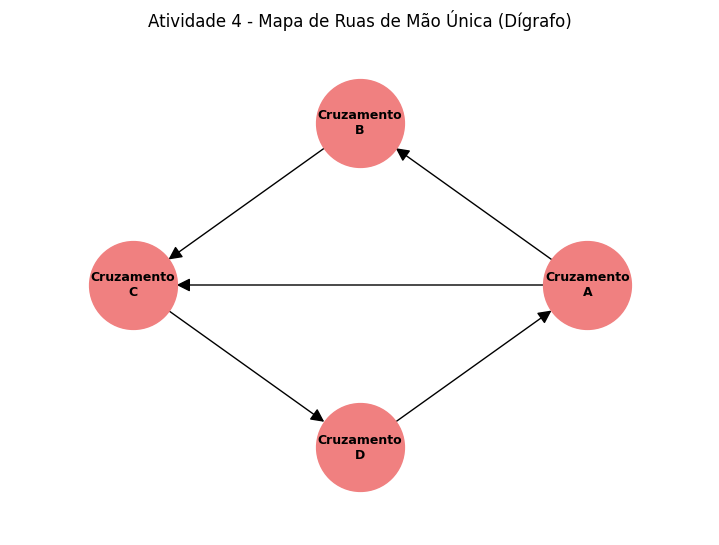

In [13]:
# Para ruas de mão única, usamos DiGraph (Grafo Dirigido), que inclui setas nas arestas
G4 = nx.DiGraph()

# Vértices representam os cruzamentos e as tuplas (origem, destino) o sentido das ruas
V4 = ["Cruzamento A", "Cruzamento B", "Cruzamento C", "Cruzamento D"]
E4 = [
    ("Cruzamento A", "Cruzamento B"),
    ("Cruzamento B", "Cruzamento C"),
    ("Cruzamento C", "Cruzamento D"),
    ("Cruzamento D", "Cruzamento A"),
    ("Cruzamento A", "Cruzamento C")
]

G4.add_nodes_from(V4)
G4.add_edges_from(E4)

# Analisando os graus de entrada (in_degree) e saída (out_degree) do Cruzamento C
no_escolhido = "Cruzamento C"
entrada = G4.in_degree(no_escolhido) # quantas setas chegam em C
saida = G4.out_degree(no_escolhido)   # quantas setas saem de C

print(f"--- Análise do {no_escolhido} ---")
print(f"Grau de entrada: {entrada}")
print(f"Grau de saída: {saida}")

# Usando layout circular para visualizar melhor a direção das setas sem sobreposição
plt.figure(figsize=(7, 5))
pos4 = nx.circular_layout(G4)
rotulos = {v: v.replace(" ", "\n") for v in G4.nodes()}  # "Cruzamento\nA"

nx.draw(G4, pos4, labels=rotulos, node_color='lightcoral',
        node_size=4000, font_weight='bold', font_size=9,
        arrows=True, arrowsize=20, edge_color='black')
plt.margins(0.2)  # evita cortar o vértice da borda
plt.title("Atividade 4 - Mapa de Ruas de Mão Única (Dígrafo)")
plt.show()

**Respostas e Justificativas - Atividade 4:**

* **Conjuntos definidos:**
  * $V = \{\text{Cruzamento A}, \text{Cruzamento B}, \text{Cruzamento C}, \text{Cruzamento D}\}$
  * $E = \{(\text{Cruzamento A}, \text{Cruzamento B}), (\text{Cruzamento B}, \text{Cruzamento C}), (\text{Cruzamento C}, \text{Cruzamento D}), (\text{Cruzamento D}, \text{Cruzamento A}), (\text{Cruzamento A}, \text{Cruzamento C})\}$
* **Grau de entrada e saída (escolhendo o Cruzamento C):**
  * **Grau de entrada = 2:** Porque existem 2 ruas que chegam nele (as setas que vêm do Cruzamento A e do Cruzamento B).
  * **Grau de saída = 1:** Porque só existe 1 rua saindo dele (a seta que vai para o Cruzamento D).
* **Por que um grafo não dirigido não é adequado?** Porque no grafo não dirigido as linhas não têm sentido, o que indicaria que os carros podem ir e voltar pela mesma via (mão dupla). Como o problema trata de ruas de **mão única**, precisamos obrigatoriamente de um **grafo dirigido** com setas para mostrar qual é a origem e o destino permitido do trânsito, evitando a contramão.

### Atividade 5 - Desafio de isomorfismo

--- Comparação dos Grafos G e H ---
Grafo G -> Ordem: 4 | Tamanho: 4 | Graus: {1: 2, 2: 2, 3: 2, 4: 2}
Grafo H -> Ordem: 4 | Tamanho: 4 | Graus: {'a': 2, 'c': 2, 'b': 2, 'd': 2}

São isomorfos? True
Correspondência entre os vértices (G -> H): {1: 'a', 2: 'c', 3: 'b', 4: 'd'}


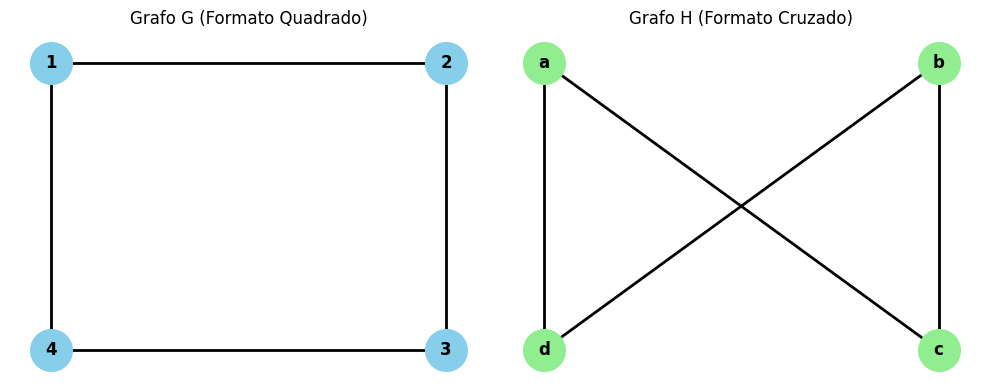

In [14]:
from networkx.algorithms import isomorphism

# Criando o Grafo G e o Grafo H para o Desafio 5
G = nx.Graph([(1, 2), (2, 3), (3, 4), (4, 1)])
H = nx.Graph([('a', 'c'), ('c', 'b'), ('b', 'd'), ('d', 'a')])

print("--- Comparação dos Grafos G e H ---")
print(f"Grafo G -> Ordem: {G.number_of_nodes()} | Tamanho: {G.number_of_edges()} | Graus: {dict(G.degree())}")
print(f"Grafo H -> Ordem: {H.number_of_nodes()} | Tamanho: {H.number_of_edges()} | Graus: {dict(H.degree())}")

# Usando o GraphMatcher do NetworkX para checar se a estrutura é isomorfa e pegar o mapeamento
verificador = isomorphism.GraphMatcher(G, H)
print(f"\nSão isomorfos? {verificador.is_isomorphic()}")
print(f"Correspondência entre os vértices (G -> H): {verificador.mapping}")

# Definindo coordenadas (x, y) fixas para desenhar o Grafo G como quadrado e o H cruzado
pos_G = {1: (0, 1), 2: (1, 1), 3: (1, 0), 4: (0, 0)}
pos_H = {'a': (0, 1), 'b': (1, 1), 'c': (1, 0), 'd': (0, 0)}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
nx.draw(G, pos_G, ax=axes[0], with_labels=True, node_color='skyblue', node_size=900, font_weight='bold', width=2)
axes[0].set_title("Grafo G (Formato Quadrado)")

nx.draw(H, pos_H, ax=axes[1], with_labels=True, node_color='lightgreen', node_size=900, font_weight='bold', width=2)
axes[1].set_title("Grafo H (Formato Cruzado)")

plt.tight_layout()
plt.show()

**Respostas e Justificativas - Atividade 5 (Desafio 5):**

1. **Ordem e tamanho de cada grafo:**
   * **Grafo $G$:** Ordem = **4** (4 vértices) e Tamanho = **4** (4 arestas).
   * **Grafo $H$:** Ordem = **4** (4 vértices) e Tamanho = **4** (4 arestas).

2. **Grau de cada vértice e sequência de graus:**
   * **Em $G$:** $d(1)=2, d(2)=2, d(3)=2, d(4)=2$ $\rightarrow$ Sequência de graus: **$(2, 2, 2, 2)$**.
   * **Em $H$:** $d(a)=2, d(b)=2, d(c)=2, d(d)=2$ $\rightarrow$ Sequência de graus: **$(2, 2, 2, 2)$**.

3. **Correspondência entre os vértices de $G$ e $H$:**

| Vértice em $G$ | Correspondente em $H$ |
| :---: | :---: |
| **1** | **a** |
| **2** | **c** |
| **3** | **b** |
| **4** | **d** |

4. **Verificação aresta por aresta (preservação das adjacências):**
   Trocando cada número de $G$ pela letra correspondente em $H$, vemos que todas as conexões continuam iguais:
   * Aresta $(1, 2)$ em $G$ corresponde a $(a, c)$ em $H$.
   * Aresta $(2, 3)$ em $G$ corresponde a $(c, b)$ em $H$.
   * Aresta $(3, 4)$ em $G$ corresponde a $(b, d)$ em $H$.
   * Aresta $(4, 1)$ em $G$ corresponde a $(d, a)$ em $H$.

5. **Conclusão e Justificativa:**
   **Sim, os grafos $G$ e $H$ são isomorfos.** Mesmo que o desenho de $H$ tenha linhas se cruzando no meio e $G$ seja um quadrado aberto, a estrutura de conexões é exatamente a mesma: ambos têm a mesma ordem, o mesmo tamanho, a mesma sequência de graus e mantêm os mesmos vizinhos através da correspondência (ambos formam um ciclo de 4 vértices).

* **Reflexão — Ter a mesma sequência de graus é suficiente para garantir isomorfismo? Explique:**
  **Não.** Ter a mesma sequência de graus é necessário, mas não garante sozinho que dois grafos sejam isomorfos. Dois grafos podem ter os mesmos graus e estruturas diferentes (por exemplo, um único ciclo fechado com 6 vértices e dois triângulos separados têm exatamente a mesma sequência de graus $(2, 2, 2, 2, 2, 2)$, mas não são isomorfos porque o primeiro é conexo e o segundo é desconexo). Para garantir o isomorfismo, além dos graus iguais, é obrigatório existir um mapeamento que preserve todas as adjacências entre os vizinhos.
  

### Atividade 6 - Construindo subgrafos

--- Verificação dos Subgrafos ---
H1 -> Vértices estão em G? True | Arestas estão em G? True
H2 -> Vértices estão em G? True | Arestas estão em G? True


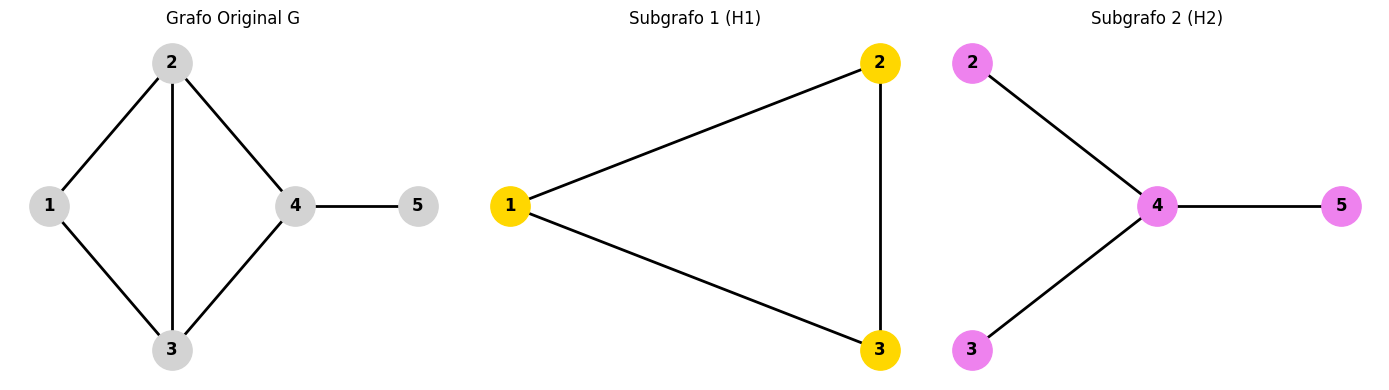

In [15]:
# Grafo principal G de onde vamos extrair os subgrafos
G_original = nx.Graph([(1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 5)])

# Criando o Subgrafo H1 pegando apenas o triângulo formado pelos vértices 1, 2 e 3
H1 = nx.Graph([(1, 2), (1, 3), (2, 3)])

# Criando o Subgrafo H2 pegando uma parte diferente do grafo original (vértices 2, 3, 4 e 5)
H2 = nx.Graph([(2, 4), (3, 4), (4, 5)])

print("--- Verificação dos Subgrafos ---")
# Verificando se todos os nós e arestas de H1 e H2 existem dentro do G_original
v1_ok = set(H1.nodes()).issubset(G_original.nodes())
e1_ok = all(G_original.has_edge(u, v) for u, v in H1.edges())

v2_ok = set(H2.nodes()).issubset(G_original.nodes())
e2_ok = all(G_original.has_edge(u, v) for u, v in H2.edges())

print(f"H1 -> Vértices estão em G? {v1_ok} | Arestas estão em G? {e1_ok}")
print(f"H2 -> Vértices estão em G? {v2_ok} | Arestas estão em G? {e2_ok}")

# Mantendo a mesma coordenada para facilitar a comparação visual com o grafo original
pos_fixa = {1: (0, 1), 2: (1, 2), 3: (1, 0), 4: (2, 1), 5: (3, 1)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

nx.draw(G_original, pos_fixa, ax=axes[0], with_labels=True, node_color='lightgray', node_size=800, font_weight='bold', width=2)
axes[0].set_title("Grafo Original G")

nx.draw(H1, pos_fixa, ax=axes[1], with_labels=True, node_color='gold', node_size=800, font_weight='bold', width=2)
axes[1].set_title("Subgrafo 1 (H1)")

nx.draw(H2, pos_fixa, ax=axes[2], with_labels=True, node_color='violet', node_size=800, font_weight='bold', width=2)
axes[2].set_title("Subgrafo 2 (H2)")

plt.tight_layout()
plt.show()


**Respostas e Justificativas - Atividade 6:**

* **Grafo Original $G$:** $V = \{1, 2, 3, 4, 5\}$ e $E = \{(1,2), (1,3), (2,3), (2,4), (3,4), (4,5)\}$.
* **Subgrafo 1 ($H_1$):**
  * $V_1 = \{1, 2, 3\}$
  * $E_1 = \{(1,2), (1,3), (2,3)\}$
* **Subgrafo 2 ($H_2$):**
  * $V_2 = \{2, 3, 4, 5\}$
  * $E_2 = \{(2,4), (3,4), (4,5)\}$
* **Confirmação e justificativa:** Tanto $H_1$ quanto $H_2$ são subgrafos válidos de $G$ porque nós não inventamos nenhum vértice e nenhuma aresta nova. Todos os vértices escolhidos para $V_1$ e $V_2$ fazem parte do conjunto original $V$ ($V_1 \subseteq V$ e $V_2 \subseteq V$), e todas as arestas de $E_1$ e $E_2$ já existiam no conjunto original $E$ ($E_1 \subseteq E$ e $E_2 \subseteq E$).

### Atividade 7 - Desafio da sequência de graus

--- Resultados do Desafio 7 ---
Conjunto de arestas E (12 arestas): [('A', 'G'), ('B', 'H'), ('C', 'H'), ('C', 'F'), ('D', 'H'), ('D', 'F'), ('D', 'E'), ('E', 'H'), ('E', 'G'), ('F', 'H'), ('F', 'G'), ('G', 'H')]

Grau obtido por vértice:
  Vértice A: grau 1
  Vértice B: grau 1
  Vértice C: grau 2
  Vértice D: grau 3
  Vértice E: grau 3
  Vértice F: grau 4
  Vértice G: grau 4
  Vértice H: grau 6

Sequência obtida (ordenada): [1, 1, 2, 3, 3, 4, 4, 6]
Sequência solicitada:        [1, 1, 2, 3, 3, 4, 4, 6]
Soma dos graus: 24
Número de arestas (|E|): 12
Verificação (Soma = 2 x |E|): 24 == 24 -> True


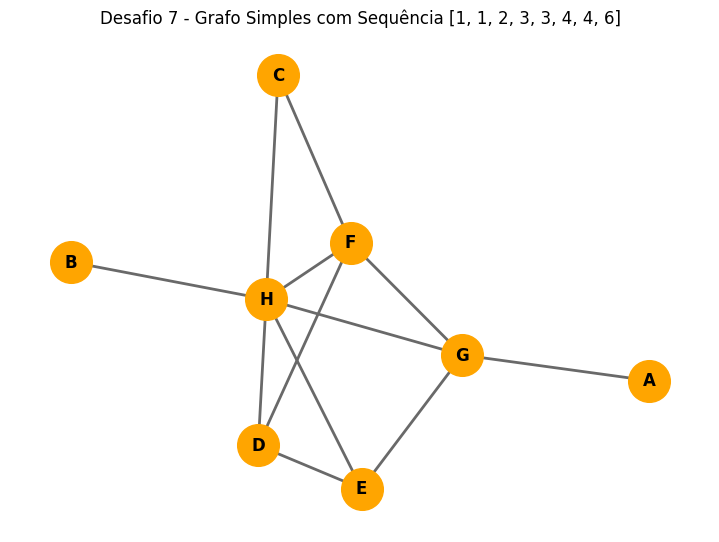

In [16]:
# Sequência solicitada pela professora no Desafio 7 (ordem não decrescente)
seq_solicitada = [1, 1, 2, 3, 3, 4, 4, 6]

# 1. Criando o grafo simples com os 8 vértices (A até H)
G7 = nx.Graph()
vertices_G7 = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
G7.add_nodes_from(vertices_G7)

# 2. Adicionando as arestas começando pelo vértice de maior grau (H terá grau 6)
# Graus planejados: A=1, B=1, C=2, D=3, E=3, F=4, G=4, H=6
arestas_G7 = [
    # 6 conexões partindo de H (ligando H a B, C, D, E, F, G -> fecha H com grau 6 e B com grau 1)
    ('H', 'B'), ('H', 'C'), ('H', 'D'), ('H', 'E'), ('H', 'F'), ('H', 'G'),
    # Conexões restantes de G (precisa de mais 3 para chegar a grau 4: liga com A, F, E -> fecha A com grau 1)
    ('G', 'A'), ('G', 'F'), ('G', 'E'),
    # Conexões restantes de F (já tem H e G, precisa de mais 2 para grau 4: liga com D, C -> fecha C com grau 2)
    ('F', 'D'), ('F', 'C'),
    # Conexão final entre D e E (ambos já tinham 2 ligações, com mais esta fecham com grau 3)
    ('D', 'E')
]

G7.add_edges_from(arestas_G7)

# 3, 4 e 5. Calculando graus, sequência ordenada e verificando o Teorema do Aperto de Mão
graus_obtidos = dict(G7.degree())
seq_obtida = sorted(graus_obtidos.values())
soma_graus = sum(seq_obtida)
num_arestas = G7.number_of_edges()

print("--- Resultados do Desafio 7 ---")
print(f"Conjunto de arestas E ({num_arestas} arestas): {list(G7.edges())}\n")
print("Grau obtido por vértice:")
for v in vertices_G7:
    print(f"  Vértice {v}: grau {graus_obtidos[v]}")

print(f"\nSequência obtida (ordenada): {seq_obtida}")
print(f"Sequência solicitada:        {seq_solicitada}")
print(f"Soma dos graus: {soma_graus}")
print(f"Número de arestas (|E|): {num_arestas}")
print(f"Verificação (Soma = 2 x |E|): {soma_graus} == {2 * num_arestas} -> {soma_graus == 2 * num_arestas}")

# Desenhando o grafo construído
plt.figure(figsize=(7, 5))
pos7 = nx.spring_layout(G7, seed=15)
nx.draw(G7, pos7, with_labels=True, node_color='orange', node_size=900, font_weight='bold', edge_color='dimgray', width=2)
plt.title(f"Desafio 7 - Grafo Simples com Sequência {seq_obtida}")
plt.show()

**Respostas e Justificativas - Desafio 7 (Sequência de Graus):**

1. **Identificação dos vértices e estratégia de construção:**
   Foram definidos os 8 vértices $V = \{A, B, C, D, E, F, G, H\}$. Seguindo a dica do roteiro, a construção começou pelo vértice **$H$** (escolhido para ter o maior grau, $d(H)=6$), conectando-o a 6 vizinhos diferentes ($B, C, D, E, F, G$). Em seguida, foram completadas as ligações dos vértices de grau 4 ($G$ e $F$), depois os de grau 3 ($D$ e $E$), até que todos atingissem a meta sem precisar de laços ou arestas paralelas.

2. **Tabela de Graus Obtidos:**

| Vértice | Grau obtido | Vizinhos conectados |
| :---: | :---: | :--- |
| **A** | **1** | $\{G\}$ |
| **B** | **1** | $\{H\}$ |
| **C** | **2** | $\{H, F\}$ |
| **D** | **3** | $\{H, F, E\}$ |
| **E** | **3** | $\{H, G, D\}$ |
| **F** | **4** | $\{H, G, D, C\}$ |
| **G** | **4** | $\{H, A, F, E\}$ |
| **H** | **6** | $\{B, C, D, E, F, G\}$ |

3. **Registro dos resultados e verificação matemática:**
   * **Conjunto de arestas $E$:** $E = \{(H,B), (H,C), (H,D), (H,E), (H,F), (H,G), (G,A), (G,F), (G,E), (F,D), (F,C), (D,E)\}$
   * **Sequência obtida:** $(1, 1, 2, 3, 3, 4, 4, 6)$ — bate exatamente com a sequência solicitada.
   * **Soma dos graus:** $1 + 1 + 2 + 3 + 3 + 4 + 4 + 6 = \mathbf{24}$.
   * **Número de arestas ($|E|$):** $\mathbf{12}$ arestas.
   * **Verificação ($\text{soma dos graus} = 2 \times \text{número de arestas}$?):** **Sim**, pois $24 = 2 \times 12$. Isso confirma matematicamente a coerência do grafo construído (como cada aresta conecta 2 vértices, ela contribui com 2 unidades na soma total dos graus). Além disso, o grafo é **simples**, pois não contém laços nem arestas paralelas.

### Checklist de Revisão
- [x] Identifiquei corretamente vértices e arestas.
- [x] Diferenciei grafo dirigido e não dirigido.
- [x] Identifiquei incidência e adjacência.
- [x] Calculei os graus quando solicitado.
- [x] Considerei o laço corretamente no cálculo do grau.
- [x] Utilizei setas nos grafos dirigidos.
- [x] Justifiquei a análise de isomorfismo.
- [x] Identifiquei corretamente os subgrafos.
- [x] Conferi a sequência de graus.
- [x] Registrei a plataforma utilizada.